# Data Explorer

What makes the five genres different, and where do they overlap?

I use the whole cleaned dataset for genre counts. The feature plots and summaries use the shared training rows so the test set stays available for evaluation.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Use the same loader as the other project notebooks.
if not Path("common.py").is_file():
    sys.path.insert(0, "../..")

from common import FEATURES, load

d = load()
songs = d.songs
train = songs[songs["split"] == "train"]
test = songs[songs["split"] == "test"]

print(f"{len(songs):,} songs")
print(f"{len(train):,} training songs, {len(test):,} test songs")

45,046 songs
36,037 training songs, 9,009 test songs


## 1. Genre counts and class imbalance

The response variable is `broad_genre`. In this dataset, only 4.2% of the songs are hip-hop/R&B. A classifier could have good overall accuracy while missing many songs in that class. That is why we also look at each genre in the confusion matrix.

split,train,test,total,percent
broad_genre,,,,
electronic,10920,2730,13650,30.3
rock,9529,2383,11912,26.4
pop,8165,2041,10206,22.7
latin,5898,1474,7372,16.4
hiphop/rnb,1525,381,1906,4.2


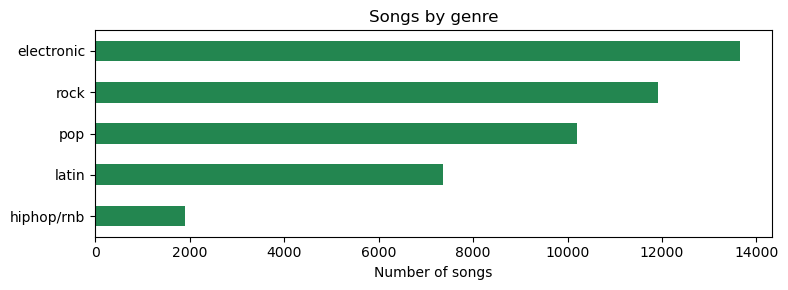

In [2]:
genre_counts = songs["broad_genre"].value_counts()
genre_order = genre_counts.index
genre_percent = 100 * genre_counts / len(songs)

counts_by_split = pd.crosstab(songs["broad_genre"], songs["split"])
counts_by_split = counts_by_split.loc[genre_order, ["train", "test"]]
counts_by_split["total"] = genre_counts
counts_by_split["percent"] = genre_percent.round(1)
display(counts_by_split)

ax = genre_counts.sort_values().plot.barh(figsize=(8, 3), color="#238650")
ax.set(title="Songs by genre", xlabel="Number of songs", ylabel="")
plt.tight_layout()
plt.show()

## 2. Comparing genres with boxplots

The line inside each box is the median. The box shows the middle 50% of the songs in that genre. The whiskers here show the 10th and 90th percentiles to match the slides.

Rock has the highest median energy. Hip-hop/R&B has the highest median danceability, and Latin has the highest median acousticness. The boxes also show how much the scores vary within each genre.

,danceability,energy,acousticness
broad_genre,,,
electronic,0.645,0.771,0.0268
rock,0.458,0.861,0.0047
pop,0.609,0.657,0.2280
latin,0.618,0.688,0.4735
hiphop/rnb,0.692,0.601,0.3000


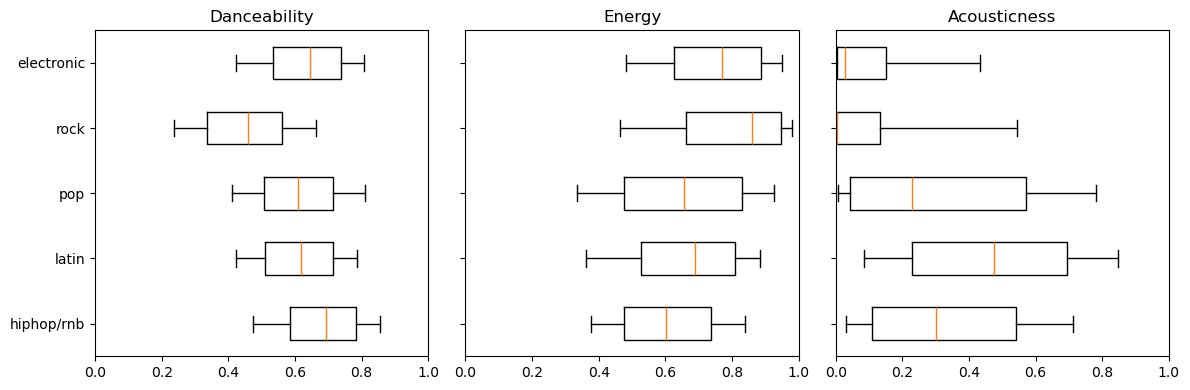

In [3]:
profile_features = ["danceability", "energy", "acousticness"]
medians = train.groupby("broad_genre")[profile_features].median()
display(medians.loc[genre_order].round(4))

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for feature, ax in zip(profile_features, axes):
    values_by_genre = []
    for genre in genre_order:
        values_by_genre.append(train.loc[train["broad_genre"] == genre, feature])

    ax.boxplot(values_by_genre, vert=False, whis=(10, 90), showfliers=False)
    ax.set_title(feature.capitalize())
    ax.set_xlim(0, 1)

axes[0].set_yticks(range(1, len(genre_order) + 1), genre_order)
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

## 3. Scatterplots for overlap

Each panel uses 300 randomly sampled training songs and the same two axes. The equal sample sizes make it easier to compare the shape of each cloud. The clouds overlap, so songs from different genres can have similar energy and danceability.

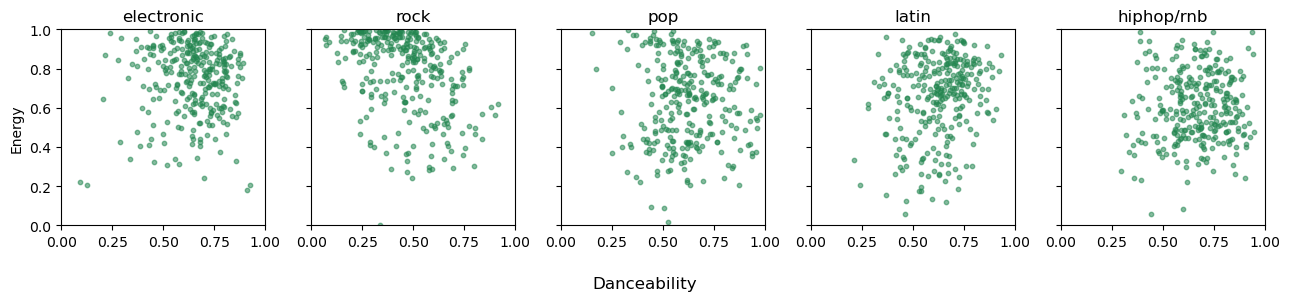

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3), sharex=True, sharey=True)
samples = []

for genre, ax in zip(genre_order, axes):
    group = train[train["broad_genre"] == genre]
    sample = group.sample(n=300, random_state=42)
    samples.append(sample)

    ax.scatter(sample["danceability"], sample["energy"], s=10, alpha=0.55, color="#238650")
    ax.set(title=genre, xlim=(0, 1), ylim=(0, 1))

overlap_sample = pd.concat(samples, ignore_index=True)
fig.supxlabel("Danceability")
axes[0].set_ylabel("Energy")
fig.tight_layout()
plt.show()

## 4. Pearson correlation

This table compares pairs of continuous predictors. Energy and loudness have a positive linear association (`r = 0.69`). Energy and acousticness have a negative one (`r = -0.64`). The sign tells us the direction and the magnitude tells us the strength of the linear association. Key and mode are coded categories, so I leave them out of this table.

,danceability,energy,loudness,acousticness,valence,speechiness
danceability,1.00,-0.16,-0.05,0.07,0.42,0.09
energy,-0.16,1.00,0.69,-0.64,0.05,0.11
loudness,-0.05,0.69,1.00,-0.40,0.08,0.09
acousticness,0.07,-0.64,-0.40,1.00,0.15,-0.07
valence,0.42,0.05,0.08,0.15,1.00,0.03
speechiness,0.09,0.11,0.09,-0.07,0.03,1.00


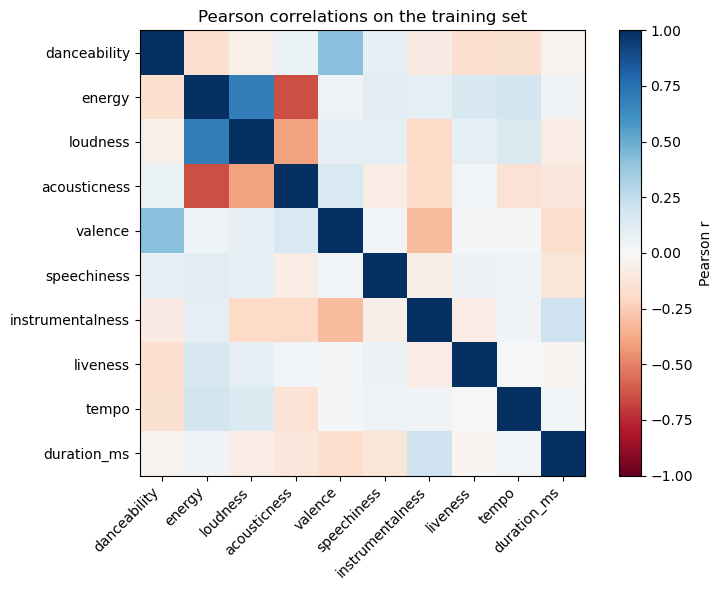

In [5]:
continuous_features = [
    "danceability", "energy", "loudness", "acousticness", "valence",
    "speechiness", "instrumentalness", "liveness", "tempo", "duration_ms",
]
correlation = train[continuous_features].corr(method="pearson")
main_features = continuous_features[:6]

display(correlation.loc[main_features, main_features].round(2))

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlation, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(continuous_features)), continuous_features, rotation=45, ha="right")
ax.set_yticks(range(len(continuous_features)), continuous_features)
ax.set_title("Pearson correlations on the training set")
fig.colorbar(image, ax=ax, label="Pearson r")
fig.tight_layout()
plt.show()

## 5. Feature scale and standardization

A typical song is 218,786 milliseconds long, while the median energy score is 0.743. The inputs use different units. Standardization subtracts the training mean and divides by the training standard deviation.

The example below uses `ddof=0` to match `StandardScaler`. In cross-validation, the shared logistic regression pipeline fits its scaler inside each training fold. This example just shows the calculation on two columns.

In [6]:
x = train[["duration_ms", "energy"]]
z = (x - x.mean()) / x.std(ddof=0)

scale_summary = pd.DataFrame({
    "raw median": x.median(),
    "raw standard deviation": x.std(ddof=0),
    "standardized mean": z.mean(),
    "standardized standard deviation": z.std(ddof=0),
})
display(scale_summary.round(3))

,raw median,raw standard deviation,standardized mean,standardized standard deviation
duration_ms,218786.000,111795.706,0.0,1.0
energy,0.743,0.210,-0.0,1.0


## 6. Data checks

There is one row with zero duration and missing artist and title fields. The project uses the same cleaned dataset for all sections. The artist check below compares exact field values, including any collaboration names stored together in a field.

In [7]:
train_artists = set(train["artists"].dropna())
test_artists = set(test["artists"].dropna())

print("Missing predictor values:", songs[FEATURES].isna().sum().sum())
print("Duplicate track IDs:", songs["track_id"].duplicated().sum())
print("Tracks with zero duration:", (songs["duration_ms"] == 0).sum())
print("Exact artist fields in both splits:", len(train_artists & test_artists))

Missing predictor values: 0
Duplicate track IDs: 0
Tracks with zero duration: 1
Exact artist fields in both splits: 0


Data comes from the shared `common.py` loader. [Spotify audio feature definitions](https://developer.spotify.com/documentation/web-api/reference/get-audio-features). Notebook and slide development used Codex assistance.